# 01 · First look at the TMDB pull

Day 1 check: is the raw pull (`data/raw/tmdb_movies.jsonl`) good enough to start cleaning on Day 2?

1. Pull completeness
2. Coverage by decade (budget, revenue, director, certification)
3. Split sizes (train ≤2015, validation 2016–18, test 2019+)
4. Plots: budget vs revenue, score distribution, languages
5. Suspicious values (placeholder money, absurd ratios, local-currency budgets)
6. Key numbers → `data/day1_summary.json`

Nothing here changes the data; the cleaning rules are decided on Day 2 using these numbers.

In [1]:
import json
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
SUMMARY_PATH = ROOT / "data" / "day1_summary.json"

In [2]:
def load_jsonl(path):
    with path.open(encoding="utf-8") as f:
        # skip a half-written last line, in case a pull is still running
        return [json.loads(line) for line in f if line.endswith("\n")]


raw = load_jsonl(RAW_DIR / "tmdb_movies.jsonl")


def crew_names(movie, job):
    return [c["name"] for c in movie["crew"] if c["job"] == job]


df = pd.DataFrame(
    {
        "id": m["id"],
        "title": m["title"],
        "original_language": m["original_language"],
        "release_date": m["release_date"],
        "status": m["status"],
        "runtime": m["runtime"],
        "budget": m["budget"],
        "revenue": m["revenue"],
        "vote_count": m["vote_count"],
        "vote_average": m["vote_average"],
        "us_certification": m["us_certification"],
        "director": ", ".join(crew_names(m, "Director")) or None,
        "n_cast": len(m["cast"]),
        "n_keywords": len(m["keywords"]),
        "has_collection": m["collection"] is not None,
        "has_overview": bool((m["overview"] or "").strip()),
        "has_poster": bool(m["poster_path"]),
    }
    for m in raw
)
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["year"] = df["release_date"].dt.year.astype("Int64")
df["decade"] = (df["year"] // 10 * 10).astype("Int64")
df["has_budget"] = df["budget"] > 0
df["has_revenue"] = df["revenue"] > 0
df["has_money"] = df["has_budget"] & df["has_revenue"]
df["has_director"] = df["director"].notna()
df["has_cert"] = df["us_certification"].notna()

print(f"{len(df):,} films loaded")
df.head()

46,199 films loaded


,id,title,original_language,release_date,status,runtime,budget,revenue,vote_count,vote_average,us_certification,director,n_cast,n_keywords,has_collection,has_overview,has_poster,year,decade,has_budget,has_revenue,has_money,has_director,has_cert
0,475557,Joker,en,2019-10-01,Released,122,55000000,1078958629,28543,8.114,R,Todd Phillips,15,18,True,True,True,2019,2010,True,True,True,True,True
1,496243,Parasite,ko,2019-05-30,Released,133,11363000,257591776,21525,8.491,R,Bong Joon Ho,15,15,False,True,True,2019,2010,True,True,True,True,True
2,299534,Avengers: Endgame,en,2019-04-24,Released,181,356000000,2938567784,29056,8.246,PG-13,"Joe Russo, Anthony Russo",15,13,True,True,True,2019,2010,True,True,True,True,True
3,429617,Spider-Man: Far From Home,en,2019-06-28,Released,129,160000000,1132723226,17774,7.388,PG-13,Jon Watts,15,15,True,True,True,2019,2010,True,True,True,True,True
4,466272,Once Upon a Time... in Hollywood,en,2019-07-24,Released,162,95000000,393869691,15428,7.417,R,Quentin Tarantino,15,25,True,True,True,2019,2010,True,True,True,True,True


## 1 · Pull completeness

In [3]:
discovered = pd.read_csv(RAW_DIR / "discover_ids.csv")
missing_path = RAW_DIR / "missing_ids.txt"
missing_ids = set(map(int, missing_path.read_text().split())) if missing_path.exists() else set()

n_discovered = discovered["id"].nunique()
not_fetched = set(discovered["id"]) - set(df["id"]) - missing_ids

completeness = {
    "discovered": n_discovered,
    "saved": len(df),
    "missing_404": len(missing_ids),
    "not_fetched": len(not_fetched),
    "duplicate_ids_in_file": int(df["id"].duplicated().sum()),
    "no_release_date": int(df["release_date"].isna().sum()),
}
print(completeness)
print("\nStatus:", df["status"].value_counts().to_dict())

per_year = discovered.groupby("year")["id"].nunique()
print(f"\nFilms discovered per year: min {per_year.min()} ({per_year.idxmin()}), max {per_year.max()}")
per_year[per_year < 700]

{'discovered': 46199, 'saved': 46199, 'missing_404': 0, 'not_fetched': 0, 'duplicate_ids_in_file': 0, 'no_release_date': 0}

Status: {'Released': 46199}

Films discovered per year: min 699 (2005), max 700


year
2005    699
Name: id, dtype: int64

In [4]:
# Discover year (primary release year) vs the release_date TMDB gives on the details page
year_check =discovered.drop_duplicates("id")[["id", "year"]].rename(columns={"year": "discover_year"}).merge(
    df[["id", "year"]], on="id"
)
print(f"Films whose details release year differs from the discover year: {(year_check['discover_year'] != year_check['year']).sum():,}")

Films whose details release year differs from the discover year: 0


## 2 · Coverage by decade

In [5]:
coverage_cols = {
    "has_budget": "budget",
    "has_revenue": "revenue",
    "has_money": "budget & revenue",
    "has_director": "director",
    "has_cert": "US cert",
    "has_overview": "overview",
}
by_decade = df.groupby("decade").agg(films=("id", "size"), **{v: (k, "mean") for k, v in coverage_cols.items()})
by_decade["keywords (≥1)"] = df.assign(k=df["n_keywords"] > 0).groupby("decade")["k"].mean()
pct_cols = by_decade.columns.drop("films")
by_decade.style.format({c: "{:.0%}" for c in pct_cols} | {"films": "{:,}"})

,films,budget,revenue,budget & revenue,director,US cert,overview,keywords (≥1)
decade,,,,,,,,
1960,"7,000",7%,6%,4%,100%,21%,99%,69%
1970,"7,000",11%,9%,7%,100%,34%,99%,74%
1980,"7,000",20%,23%,15%,100%,41%,99%,75%
1990,"7,000",28%,32%,23%,100%,50%,100%,79%
2000,"6,999",46%,48%,37%,100%,61%,100%,86%
2010,"7,000",47%,55%,38%,100%,68%,100%,90%
2020,"4,200",31%,44%,26%,100%,68%,100%,86%


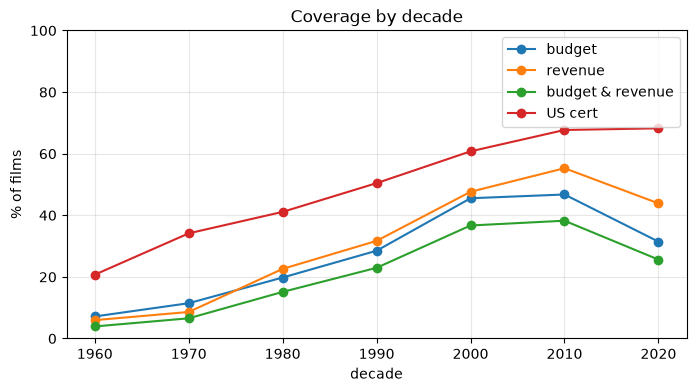

In [6]:
ax = (by_decade[["budget", "revenue", "budget & revenue", "US cert"]] * 100).plot(marker="o", figsize=(8, 4))
ax.set(title="Coverage by decade", xlabel="decade", ylabel="% of films", ylim=(0, 100))
ax.grid(alpha=0.3)
plt.show()

## 3 · Split sizes

In [7]:
def split_of(year):
    if pd.isna(year):
        return "unknown"
    return "train (≤2015)" if year <= 2015 else "validation (2016–18)" if year <= 2018 else "test (2019+)"


df["split"] = df["year"].map(split_of)
split_order = ["train (≤2015)", "validation (2016–18)", "test (2019+)"]

splits = pd.DataFrame(
    {
        "all films": df["split"].value_counts(),
        "budget & revenue": df[df["has_money"]]["split"].value_counts(),
        "budget": df[df["has_budget"]]["split"].value_counts(),
        "votes ≥ 10": df[df["vote_count"] >= 10]["split"].value_counts(),
        "votes ≥ 50": df[df["vote_count"] >= 50]["split"].value_counts(),
        "votes ≥ 100": df[df["vote_count"] >= 100]["split"].value_counts(),
    }
).reindex(split_order).fillna(0).astype(int)
splits

,all films,budget & revenue,budget,votes ≥ 10,votes ≥ 50,votes ≥ 100
split,,,,,,
train (≤2015),39199,7616,9917,36971,19296,14174
validation (2016–18),2100,799,958,2100,2100,2100
test (2019+),4900,1305,1590,4900,4900,4564


The vote threshold for the score target is set on Day 2; the three columns above show what 10, 50 or 100 would cost.

## 4 · Plots

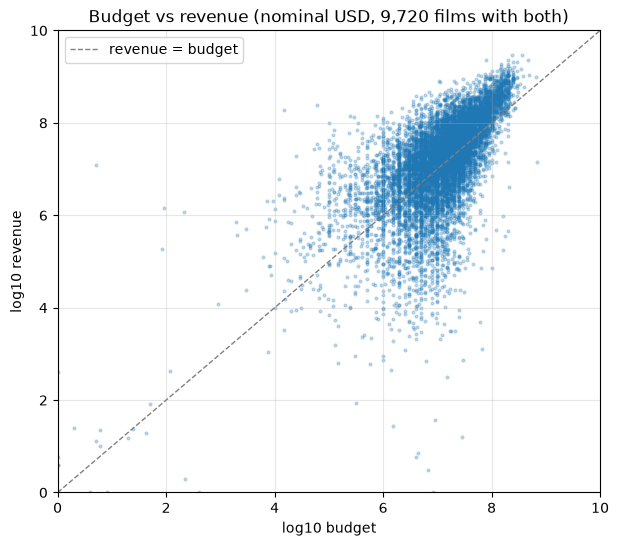

In [8]:
money = df[df["has_money"]]
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(np.log10(money["budget"]), np.log10(money["revenue"]), s=4, alpha=0.25)
lims = [0, 10]
ax.plot(lims, lims, color="grey", lw=1, ls="--", label="revenue = budget")
ax.set(
    title=f"Budget vs revenue (nominal USD, {len(money):,} films with both)",
    xlabel="log10 budget", ylabel="log10 revenue", xlim=lims, ylim=lims,
)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Points in the bottom-left corner (log10 < 3, i.e. under $1,000) are the placeholder values Day 2 will null out.

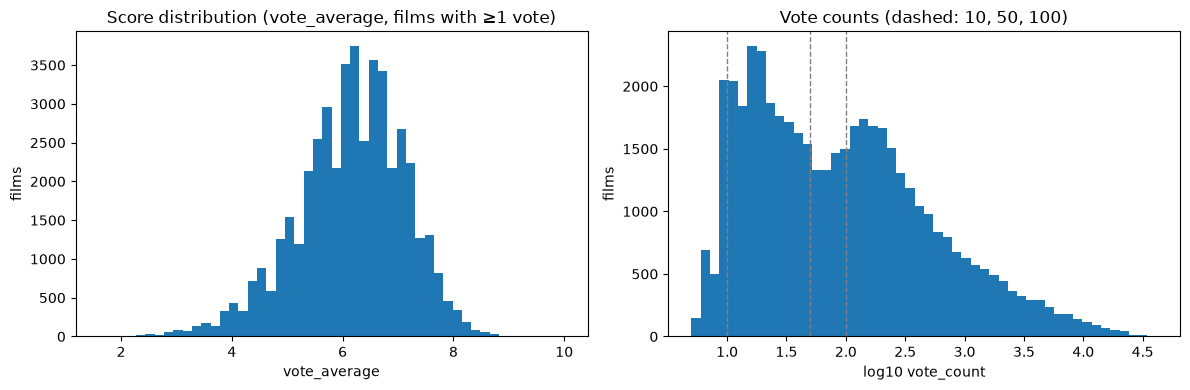

In [9]:
voted = df[df["vote_count"] > 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(voted["vote_average"], bins=50)
axes[0].set(title="Score distribution (vote_average, films with ≥1 vote)", xlabel="vote_average", ylabel="films")
axes[1].hist(np.log10(voted["vote_count"]), bins=50)
for t in (10, 50, 100):
    axes[1].axvline(np.log10(t), color="grey", ls="--", lw=1)
axes[1].set(title="Vote counts (dashed: 10, 50, 100)", xlabel="log10 vote_count", ylabel="films")
plt.tight_layout()
plt.show()

In [10]:
# Score noise vs vote count: low-vote scores spread much wider
bins = pd.cut(voted["vote_count"], [0, 10, 50, 100, 500, 1000, np.inf], right=False)
voted.groupby(bins, observed=True)["vote_average"].describe()[["count", "mean", "std", "min", "max"]]

,count,mean,std,min,max
vote_count,,,,,
"[0.0, 10.0)",2228.0,5.879103,1.009500,2.375,9.000
"[10.0, 50.0)",17675.0,5.841004,1.029709,1.700,10.000
"[50.0, 100.0)",5458.0,6.137922,0.931913,1.600,9.013
"[100.0, 500.0)",12956.0,6.325960,0.838145,2.000,9.900
"[500.0, 1000.0)",3009.0,6.528712,0.764402,3.339,8.442
"[1000.0, inf)",4873.0,6.763735,0.732326,2.934,8.805


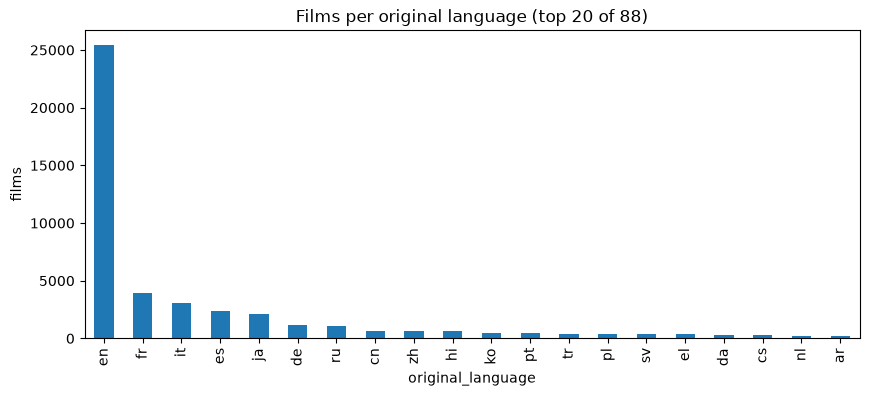

,films,budget,revenue,both
original_language,,,,
en,"25,429",40%,41%,32%
fr,"3,915",14%,19%,10%
it,"3,089",7%,11%,4%
es,"2,376",10%,14%,6%
ja,"2,132",8%,23%,6%
de,"1,158",9%,15%,4%
ru,"1,058",10%,11%,8%
cn,669,10%,26%,7%
zh,656,17%,27%,13%


In [11]:
lang_counts = df["original_language"].value_counts()
top_langs = lang_counts.head(20)
ax = top_langs.plot.bar(figsize=(10, 4))
ax.set(title=f"Films per original language (top 20 of {len(lang_counts)})", ylabel="films")
plt.show()

lang_cov = (
    df[df["original_language"].isin(top_langs.index)]
    .groupby("original_language")
    .agg(films=("id", "size"), budget=("has_budget", "mean"), revenue=("has_revenue", "mean"), both=("has_money", "mean"))
    .sort_values("films", ascending=False)
)
lang_cov.style.format({"budget": "{:.0%}", "revenue": "{:.0%}", "both": "{:.0%}", "films": "{:,}"})

## 5 · Suspicious values

In [12]:
def show(frame, n=10):
    cols = ["id", "title", "year", "original_language", "budget", "revenue", "vote_count"]
    return frame.sort_values("vote_count", ascending=False)[cols].head(n)


tiny_budget = df[(df["budget"] > 0) & (df["budget"] < 1000)]
tiny_revenue = df[(df["revenue"] > 0) & (df["revenue"] < 1000)]
print(f"Budget between $1 and $999: {len(tiny_budget):,} films")
print(f"Revenue between $1 and $999: {len(tiny_revenue):,} films")
show(tiny_budget)

Budget between $1 and $999: 87 films
Revenue between $1 and $999: 96 films


,id,title,year,original_language,budget,revenue,vote_count
38625,250574,Creep,2014,en,420,0,1746
43610,916405,The Quiet Girl,2022,ga,1,6,612
38789,282297,Cowspiracy: The Sustainability Secret,2014,en,117,0,535
35242,38780,Rampage,2009,en,120,428,504
36669,66125,Red Dog,2011,en,5,13,446
23924,390555,Bonanza: The Return,1993,en,93,0,404
40260,391698,The Beatles: Eight Days a Week - The Touring Y...,2016,en,5,12283800,396
24604,13701,Immortal Beloved,1994,en,120,0,386
13336,11537,Snake in the Eagle's Shadow,1978,cn,92,0,379
44394,1006462,The Flood,2023,en,2,25,297


In [13]:
show(tiny_revenue)

,id,title,year,original_language,budget,revenue,vote_count
43534,966220,Sniper: The White Raven,2022,uk,1000000,881,958
44916,1064486,Memoir of a Snail,2024,en,4350000,7,846
43610,916405,The Quiet Girl,2022,ga,1,6,612
35242,38780,Rampage,2009,en,120,428,504
30259,7294,The Man Without a Past,2002,fi,0,921,469
36669,66125,Red Dog,2011,en,5,13,446
45007,1002155,Monsieur Aznavour,2024,fr,28000000,16,372
33869,6936,Ben X,2007,nl,1500000,27,345
34572,7916,Far Cry,2008,en,30000000,743,337
45037,1045770,Daaaaaalí!,2024,fr,6700000,3,328


In [14]:
# Revenue / budget ratio among films with both values (and both ≥ $1,000)
both = df[(df["budget"] >= 1000) & (df["revenue"] >= 1000)].copy()
both["ratio"] = both["revenue"] / both["budget"]
high_ratio = both[both["ratio"] > 1000]
low_ratio = both[both["ratio"] < 0.0001]
print(f"Ratio > 1000x: {len(high_ratio):,}   ratio < 0.0001x: {len(low_ratio):,}   (of {len(both):,})")
print("\nRatio percentiles:", both["ratio"].quantile([0.01, 0.05, 0.5, 0.95, 0.99]).round(3).to_dict())
show(high_ratio).assign(ratio=high_ratio["ratio"])

Ratio > 1000x: 2   ratio < 0.0001x: 2   (of 9,680)

Ratio percentiles: {0.01: 0.004, 0.05: 0.048, 0.5: 1.699, 0.95: 14.245, 0.99: 62.265}


,id,title,year,original_language,budget,revenue,vote_count,ratio
28015,2667,The Blair Witch Project,1999,en,60000,248639099,5733,4143.984983
35031,23827,Paranormal Activity,2009,en,15000,193355800,5626,12890.386667


In [15]:
show(low_ratio).assign(ratio=low_ratio["ratio"])

,id,title,year,original_language,budget,revenue,vote_count,ratio
44127,906126,Society of the Snow,2023,es,65500000,1281,3679,0.000020
44832,763215,Damsel,2024,en,60000000,5000,2967,0.000083


In [16]:
# Budgets in local currency: per-language budget percentiles (films with budget ≥ $1,000).
# A language whose top budgets dwarf Hollywood's is a sign of rupees/yen/won entered as dollars.
budgeted = df[df["budget"] >= 1000]
top_budget_langs = budgeted["original_language"].value_counts().head(15).index
budget_pct = (
    budgeted[budgeted["original_language"].isin(top_budget_langs)]
    .groupby("original_language")["budget"]
    .describe(percentiles=[0.5, 0.9, 0.99])[["count", "50%", "90%", "99%", "max"]]
    .sort_values("count", ascending=False)
)
(budget_pct / [1, 1e6, 1e6, 1e6, 1e6]).round(1).rename(columns=lambda c: c if c == "count" else f"{c} ($M)")

,count,50% ($M),90% ($M),99% ($M),max ($M)
original_language,,,,,
en,10010.0,12.0,70.0,200.0,658.8
fr,556.0,8.0,25.0,78.3,97.3
hi,237.0,5.0,19.5,58.3,75.0
es,235.0,3.7,11.0,31.3,65.5
it,201.0,4.2,13.5,35.0,40.0
ja,171.0,5.0,20.0,39.3,50.0
ko,114.0,8.0,18.3,38.3,40.0
zh,114.0,18.5,78.1,119.6,200.0
de,107.0,4.0,17.3,31.7,67.0


In [17]:
# Largest non-English budgets: eyeball these for local-currency entries
non_en = budgeted[budgeted["original_language"] != "en"]
non_en.sort_values("budget", ascending=False)[["id", "title", "year", "original_language", "budget", "revenue", "vote_count"]].head(15)

,id,title,year,original_language,budget,revenue,vote_count
6352,29266,War and Peace,1968,ru,700000000,14000000,171
43250,779029,The Battle at Lake Changjin,2021,zh,200000000,902540935,161
45859,1155281,Creation of the Gods II: Demon Force,2025,zh,120000000,172619925,146
43375,602666,Detective Chinatown 3,2021,zh,117000000,686257563,121
45300,1229349,Yolo,2024,zh,100000000,433606094,124
34384,2395,Asterix at the Olympic Games,2008,fr,97250400,131856927,2141
29543,11444,The Closet,2001,fr,95130000,50104745,543
36581,76758,The Flowers of War,2011,zh,94000000,95311434,939
26603,18,The Fifth Element,1997,fr,90000000,263920180,12268
35104,26505,Arthur and the Revenge of Maltazard,2009,fr,87000000,52377611,1822


In [18]:
other_checks = {
    "runtime_zero_or_missing": int(((df["runtime"] == 0) | df["runtime"].isna()).sum()),
    "runtime_over_600": int((df["runtime"] > 600).sum()),
    "zero_votes": int((df["vote_count"] == 0).sum()),
    "not_released": int((df["status"] != "Released").sum()),
}
other_checks

{'runtime_zero_or_missing': 214,
 'runtime_over_600': 4,
 'zero_votes': 0,
 'not_released': 0}

## 6 · Summary → `data/day1_summary.json`

In [19]:
def pct(series):
    return round(float(series.mean()) * 100, 1)


summary = {
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "years": [int(df["year"].min()), int(df["year"].max())],
    "completeness": completeness,
    "coverage_pct": {
        "overall": {v: pct(df[k]) for k, v in coverage_cols.items()},
        "by_decade": {
            str(decade): {"films": int(row["films"]), **{c: round(float(row[c]) * 100, 1) for c in pct_cols}}
            for decade, row in by_decade.iterrows()
        },
    },
    "split_sizes": {split: {col: int(splits.loc[split, col]) for col in splits.columns} for split in split_order},
    "vote_count_quantiles": {str(q): float(v) for q, v in df["vote_count"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).items()},
    "languages_top20": {lang: int(n) for lang, n in top_langs.items()},
    "money_coverage_by_language_pct": {lang: pct_row for lang, pct_row in (lang_cov["both"] * 100).round(1).items()},
    "suspicious": {
        "budget_1_to_999": len(tiny_budget),
        "revenue_1_to_999": len(tiny_revenue),
        "ratio_over_1000x": len(high_ratio),
        "ratio_under_0.0001x": len(low_ratio),
        **other_checks,
    },
    "budget_percentiles_by_language_usd": {
        lang: {k: float(v) for k, v in row.items()} for lang, row in budget_pct.iterrows()
    },
}
SUMMARY_PATH.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(f"Saved {SUMMARY_PATH.relative_to(ROOT)}")
summary["suspicious"]

Saved data\day1_summary.json


{'budget_1_to_999': 87,
 'revenue_1_to_999': 96,
 'ratio_over_1000x': 2,
 'ratio_under_0.0001x': 2,
 'runtime_zero_or_missing': 214,
 'runtime_over_600': 4,
 'zero_votes': 0,
 'not_released': 0}

## Findings

_From the full pull: 46,199 films, 1960–2025, pulled 2026-10-21._

**Pull quality.** All 46,199 discovered films were saved: 0 missing (404), 0 failed and 0 duplicates. Every year has 700 films except 2005 with 699. All films are "Released" and have a release date, and every film's release year matches the year it was discovered under. A rerun fetches nothing.

**1. Money data is thin, which limits the revenue model.**
- Only 21% of films have both budget and revenue: 3.9% in the 1960s, 6.6% in the 1970s, 15% in the 1980s, 23% in the 1990s, 37% in the 2000s, 38% in the 2010s and 26% in the 2020s.
- The 2020s drop is probably newer films whose numbers haven't been entered on TMDB yet.

**2. Split sizes for revenue are small outside train.**

| Split | All films | Budget & revenue | Votes ≥ 50 |
| --- | --- | --- | --- |
| Train (≤2015) | 39,199 | 7,616 | 19,296 |
| Validation (2016–18) | 2,100 | 799 | 2,100 |
| Test (2019+) | 4,900 | 1,305 | 4,900 |

With 799 validation films, the Day 4 breakdowns (e.g. $150M+ budgets) will have very few films per group.

**3. The revenue model will mostly be an English-language model.**
- English: 25,429 films, 31.7% with both money values. Hindi: 34%. Korean: 17%. Chinese (`zh`): 13%. French: 9.8%. Japanese: 6.1%. Italian: 4.3%.
- This goes in the README's Limitations.
- TMDB uses `cn` (Cantonese) separately from `zh`, which matters when we group languages on Day 3.

**4. The score data is solid, and the vote threshold matters.**
- Vote counts: median 75, 10th percentile 12, 90th percentile 1,080.
- Scores spread less as votes grow: standard deviation about 1.03 below 50 votes, 0.84 at 100–500, and 0.73 at 1,000+.
- A threshold of 50 keeps all of validation and test, but cuts train from 36,971 films (≥10 votes) to 19,296. It mostly removes older films. To decide on Day 2.

**5. Placeholder money exists, but it's rare.**
- 87 budgets and 96 revenues are between $1 and $999 (e.g. Red Dog's budget is $5, The Quiet Girl's is $1, Memoir of a Snail's revenue is $7).
- Day 2's "below $1,000 → NULL" rule handles them.

**6. The planned ratio rule would flag real films.**
- Above 1000×: only 2 films, both genuine micro-budget hits: The Blair Witch Project (4,144×) and Paranormal Activity (12,890×).
- Below 0.0001×: only 2 films, both Netflix releases with token box office: Society of the Snow ($1,281) and Damsel ($5,000).
- On Day 2, rethink the high-ratio rule. The low-ratio rule usefully catches streaming films.

**7. Budgets entered in local currency look rare.**
- Each language's budgets look plausible: the median is $12M for English and $4–8M for most others, and the 99th percentile is $200M for English and $30–120M for the others.
- The one clear outlier is War and Peace (1968, Russian) at $700M, which is probably an inflation-adjusted figure.
- Day 2's per-language cap may only catch a handful of films.

**8. Other gaps.**
- US certification: only 48% of films have one (21% in the 1960s, 68% in the 2010s). It's required on the creator form, so the form needs an "unrated/unknown" option.
- Runtime: 214 films have runtime 0 or missing, and 4 are over 600 minutes.
- Director is present for 99.9% of films and overview for 99.6%. At least one keyword: 69% of 1960s films, about 90% of 2010s films.

**Verdict.** The data is good enough for Day 2. The score model has plenty of data. The revenue model rests on about 9,700 films, mostly in English, so its limits need to be stated honestly.